**Mục tiêu nghiên cứu & kỹ thuật:**
1. **Khám phá và trực quan hóa dữ liệu (EDA)**: Phân tích phân phối, tương quan, và hiện tượng mất cân bằng nhãn (Imbalanced Data).
2. **Tiền xử lý và chuẩn hóa dữ liệu**: Loại bỏ trùng lặp, mã hóa One-Hot, phân tách Stratified Split (70% Train - 15% Val - 15% Test) và chuẩn hóa đặc trưng bằng StandardScaler.
3. **Huấn luyện độc lập 5 mô hình khác biệt**:
   - Model 1: **Logistic Regression** (Mô hình tuyến tính cơ sở).
   - Model 2: **Random Forest** (Mô hình tổ hợp cây quyết định).
   - Model 3: **LightGBM** (Mô hình Gradient Boosting hiện đại).
   - Model 4: **PyTorch Deep MLP** (Mạng nơ-ron đa tầng với BatchNorm & Dropout).
   - Model 5: **PyTorch Tabular 1D-CNN** (Mạng nơ-ron tích chập 1 chiều trích xuất đặc trưng lâm sàng).
4. **Ghi nhật ký huấn luyện đầy đủ (Full Epoch Logs)**: Từng epoch của mô hình học sâu được in chi tiết (Loss, Val F1, Val AUC, Learning Rate, Time) để theo dõi quá trình hội tụ.
5. **So sánh đối chuẩn toàn diện (Comprehensive Benchmarking)**: So sánh trên tập Test độc lập qua các chỉ số Accuracy, Precision, Recall, F1-Score, ROC-AUC, PR-AUC, Latency.
6. **Giải thích mô hình với SHAP (Explainable AI - XAI)**: Bóc tách tầm quan trọng của các chỉ số (HbA1c, Glucose, BMI, Age...).
7. **Đóng gói Artifacts**: Xuất mô hình tốt nhất phục vụ tích hợp vào `RiskPredictionAgent` của hệ Multi-Agent.

In [1]:
# 1. Khai báo thư viện phục vụ nghiên cứu và thực nghiệm
import os
import sys
import time
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

# LightGBM
import lightgbm as lgb

# PyTorch Deep Learning
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Explainable AI (SHAP)
import shap

# Thiết lập tham số hiển thị & reproducibility
warnings.filterwarnings('ignore')
np.random.seed(42)
torch.manual_seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120

# Thiết bị tính toán
DEVICE = torch.device('cpu')
print(f"✓ PyTorch Version : {torch.__version__}")
print(f"✓ Computing Device: {DEVICE}")
print(f"✓ LightGBM Version: {lgb.__version__}")
print(f"✓ SHAP Version    : {shap.__version__}")


✓ PyTorch Version : 2.3.0
✓ Computing Device: cpu
✓ LightGBM Version: 4.7.0
✓ SHAP Version    : 0.54.1


---
## PHẦN 1: KHÁM PHÁ DỮ LIỆU (EXPLORATORY DATA ANALYSIS - EDA) & TRỰC QUAN HÓA

In [2]:
# 1.1 Tải tập dữ liệu 100.000 hồ sơ lâm sàng
# Tự động định vị đường dẫn dữ liệu dù chạy từ bất kỳ thư mục nào
candidate_paths = [
    os.path.abspath("src/dia_mas/data/diabetes_prediction_dataset.csv"),
    os.path.abspath("../data/diabetes_prediction_dataset.csv"),
    os.path.abspath("data/diabetes_prediction_dataset.csv")
]
DATA_PATH = next((p for p in candidate_paths if os.path.exists(p)), candidate_paths[0])
df_raw = pd.read_csv(DATA_PATH)

print(f"=== TỔNG QUAN TẬP DỮ LIỆU GỐC ===")
print(f"- Số lượng bản ghi ban đầu: {len(df_raw):,} dòng")
print(f"- Số lượng thuộc tính: {df_raw.shape[1]} cột")

# Kiểm tra trùng lặp và giá trị khuyết thiếu
num_duplicates = df_raw.duplicated().sum()
print(f"- Số lượng dòng trùng lặp: {num_duplicates:,} dòng ({num_duplicates/len(df_raw)*100:.2f}%)")
print(f"- Giá trị rỗng (Null/NaN)  : {df_raw.isnull().sum().sum()} giá trị")

# Loại bỏ trùng lặp để đảm bảo tính khách quan của thực nghiệm
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"- Số lượng bản ghi sau làm sạch: {len(df):,} dòng\n")

# Hiển thị 5 dòng đầu tiên
df.head()


=== TỔNG QUAN TẬP DỮ LIỆU GỐC ===
- Số lượng bản ghi ban đầu: 100,000 dòng
- Số lượng thuộc tính: 9 cột
- Số lượng dòng trùng lặp: 3,854 dòng (3.85%)
- Giá trị rỗng (Null/NaN)  : 0 giá trị
- Số lượng bản ghi sau làm sạch: 96,146 dòng



Nhận xét lâm sàng: Nhóm dương tính (mắc ĐTĐ) chiếm 8.82% (8,482 ca), nhóm âm tính chiếm 91.18% (87,664 ca). Tỷ số mất cân bằng là 10.34 : 1. Do đó cần áp dụng class weighting / scale_pos_weight trong loss function để tránh mô hình bị thiên lệch.


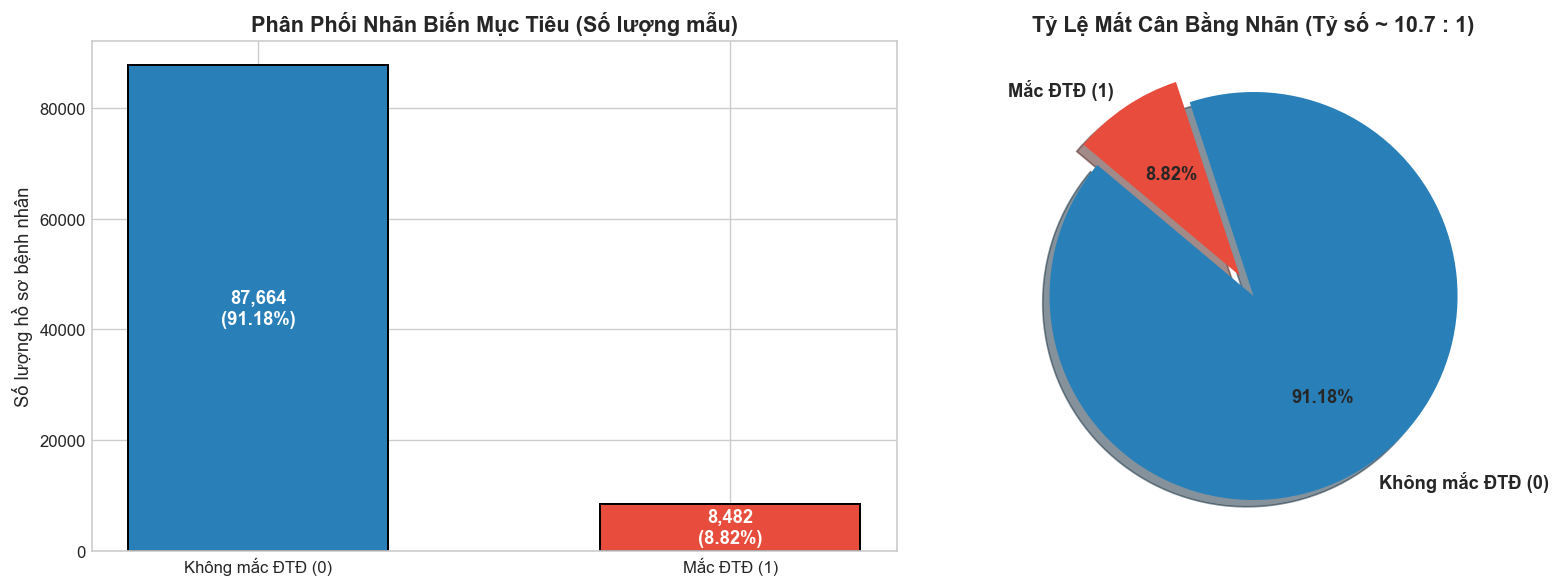

In [3]:
# 1.2 Phân tích hiện tượng mất cân bằng nhãn (Imbalanced Data)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts = df['diabetes'].value_counts()
labels = ['Không mắc ĐTĐ (0)', 'Mắc ĐTĐ (1)']
colors = ['#2980b9', '#e74c3c']

# Bar plot
bars = axes[0].bar(labels, counts.values, color=colors, width=0.55, edgecolor='black', linewidth=1.2)
axes[0].set_title('Phân Phối Nhãn Biến Mục Tiêu (Số lượng mẫu)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Số lượng hồ sơ bệnh nhân', fontsize=11)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval/2.0, f"{int(yval):,}\n({yval/len(df)*100:.2f}%)", 
                 ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Pie chart
axes[1].pie(counts.values, labels=labels, autopct='%1.2f%%', colors=colors, explode=(0, 0.12),
            shadow=True, startangle=140, textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[1].set_title('Tỷ Lệ Mất Cân Bằng Nhãn (Tỷ số ~ 10.7 : 1)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

pos_samples = counts[1]
neg_samples = counts[0]
imbalance_ratio = neg_samples / pos_samples
print(f"Nhận xét lâm sàng: Nhóm dương tính (mắc ĐTĐ) chiếm {pos_samples/len(df)*100:.2f}% ({pos_samples:,} ca), "
      f"nhóm âm tính chiếm {neg_samples/len(df)*100:.2f}% ({neg_samples:,} ca). "
      f"Tỷ số mất cân bằng là {imbalance_ratio:.2f} : 1. "
      f"Do đó cần áp dụng class weighting / scale_pos_weight trong loss function để tránh mô hình bị thiên lệch.")


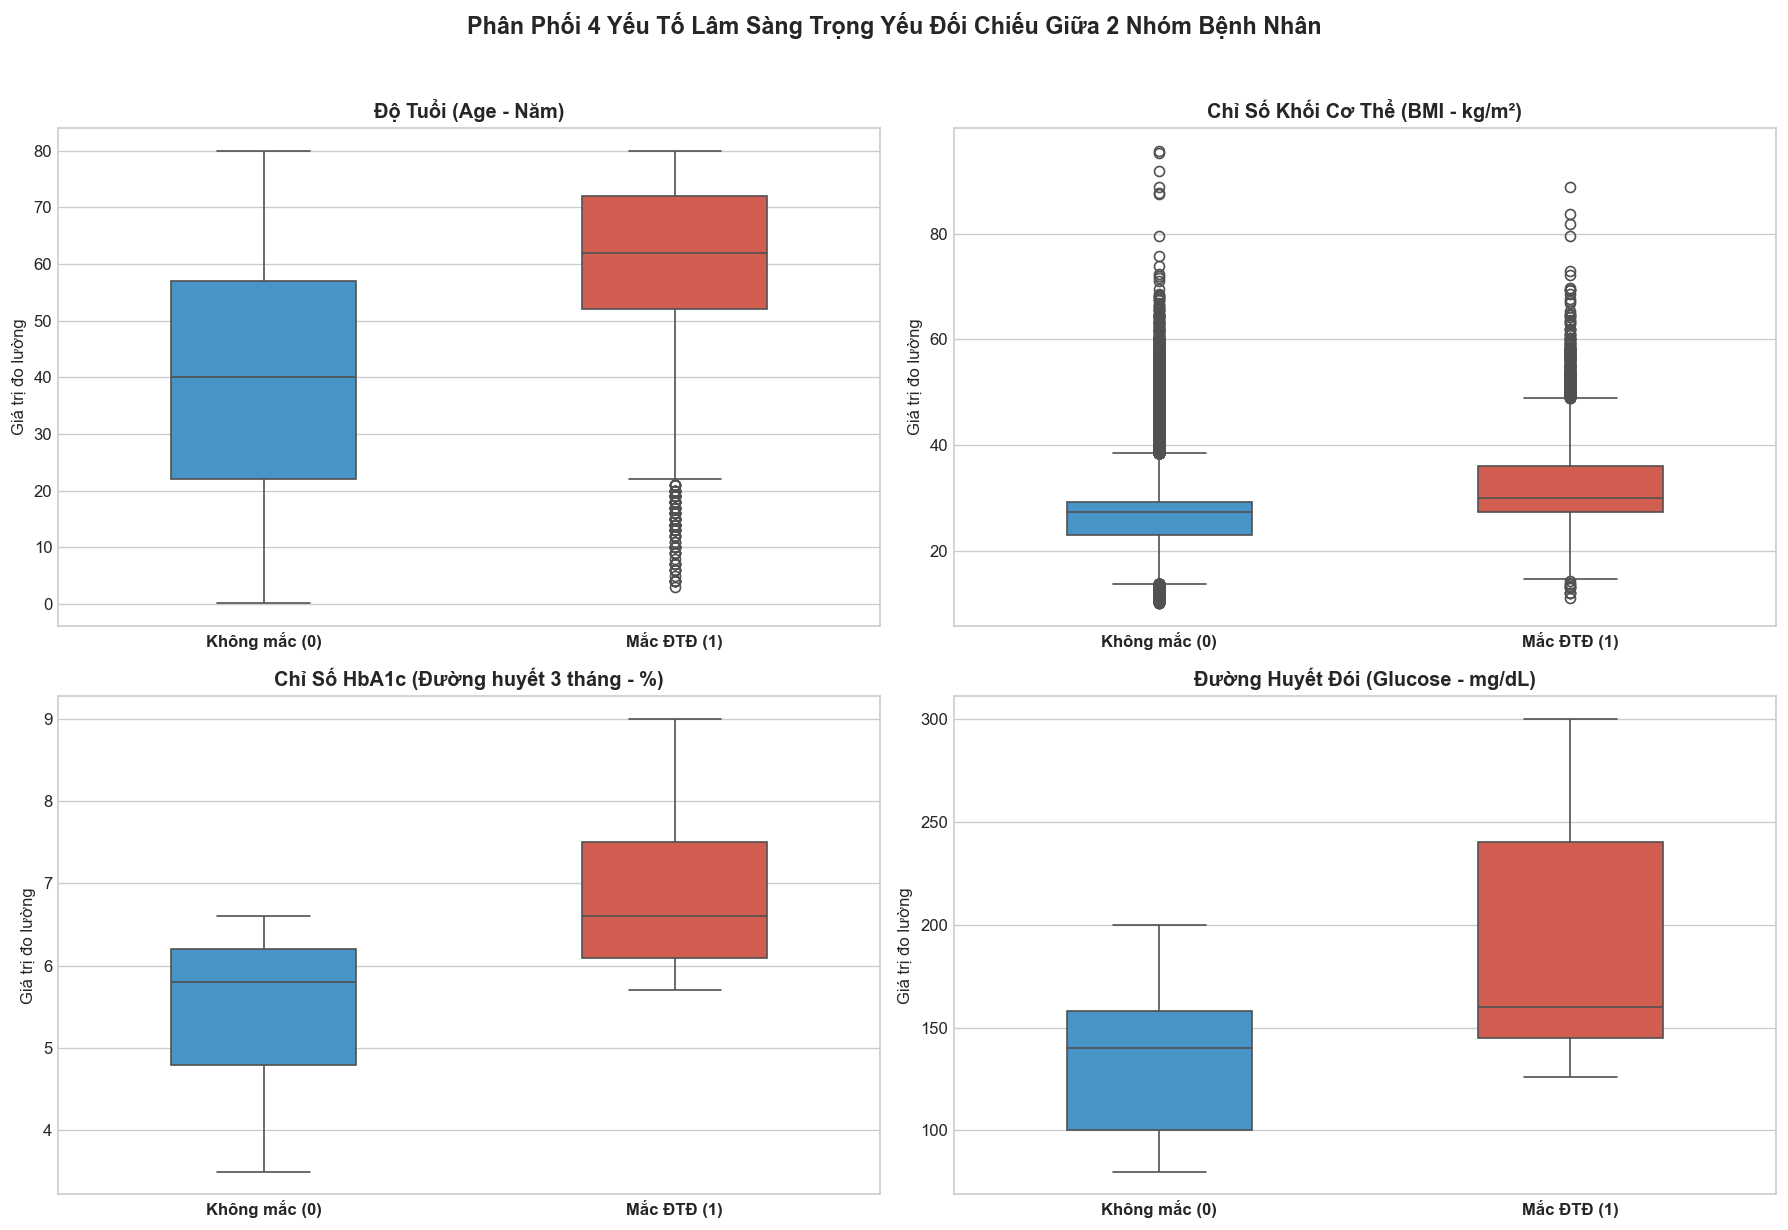

In [4]:
# 1.3 Trực quan hóa phân phối các chỉ số lâm sàng theo nhãn bệnh
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

clinical_features = [
    ('age', 'Độ Tuổi (Age - Năm)', axes[0, 0]),
    ('bmi', 'Chỉ Số Khối Cơ Thể (BMI - kg/m²)', axes[0, 1]),
    ('HbA1c_level', 'Chỉ Số HbA1c (Đường huyết 3 tháng - %)', axes[1, 0]),
    ('blood_glucose_level', 'Đường Huyết Đói (Glucose - mg/dL)', axes[1, 1])
]

for col, title, ax in clinical_features:
    sns.boxplot(data=df, x='diabetes', y=col, palette=['#3498db', '#e74c3c'], ax=ax, width=0.45)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticklabels(['Không mắc (0)', 'Mắc ĐTĐ (1)'], fontsize=10, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Giá trị đo lường', fontsize=10)

plt.suptitle('Phân Phối 4 Yếu Tố Lâm Sàng Trọng Yếu Đối Chiếu Giữa 2 Nhóm Bệnh Nhân', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


Nhận xét tương quan:
- blood_glucose_level và HbA1c_level có tương quan tuyến tính mạnh nhất với nhãn diabetes (r = 0.42 - 0.44).
- age và bmi có tương quan thuận mức độ trung bình (r = 0.21 - 0.26).


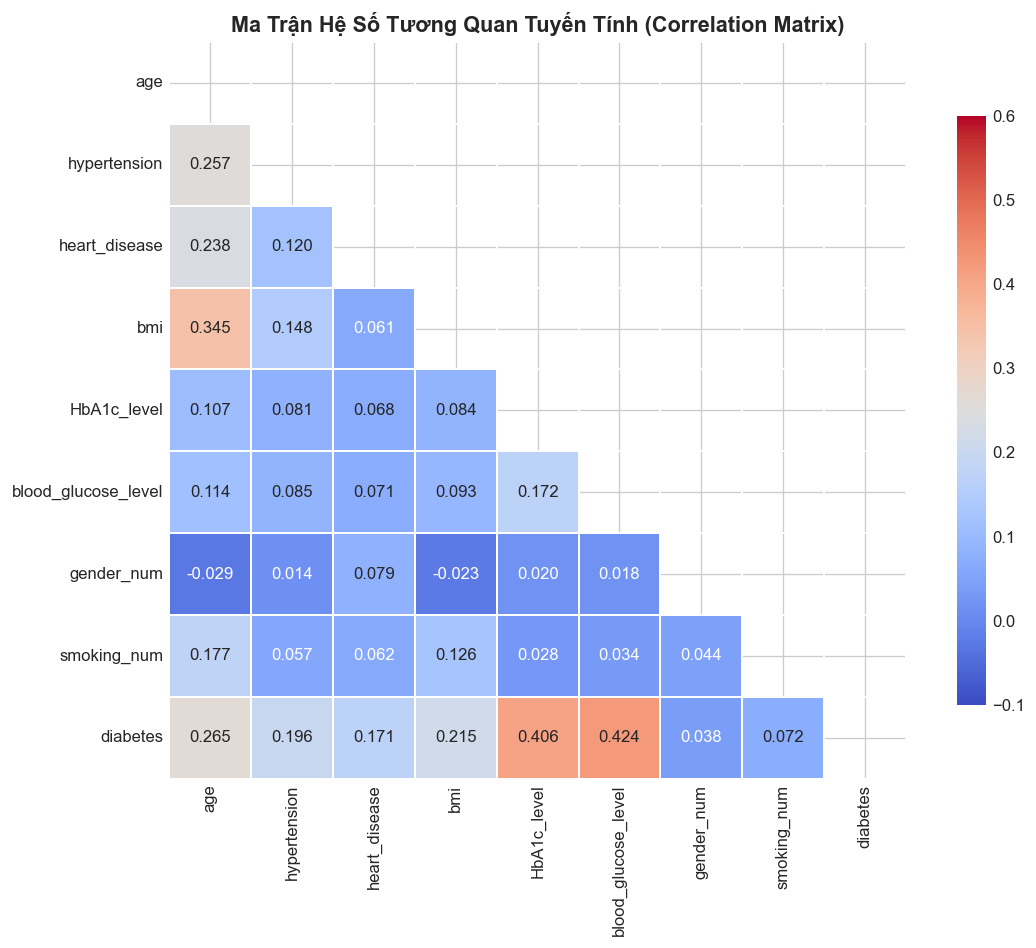

In [5]:
# 1.4 Ma trận tương quan Pearson giữa các đặc trưng
corr_df = df.copy()
corr_df['gender_num'] = corr_df['gender'].map({'Female': 0, 'Male': 1, 'Other': 0})
smoking_map = {'never': 0, 'No Info': 0, 'former': 1, 'not current': 1, 'ever': 1, 'current': 2}
corr_df['smoking_num'] = corr_df['smoking_history'].map(smoking_map)

corr_matrix = corr_df[['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_num', 'smoking_num', 'diabetes']].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-0.1, vmax=0.6,
            linewidths=1, square=True, mask=mask, cbar_kws={'shrink': 0.8})
plt.title('Ma Trận Hệ Số Tương Quan Tuyến Tính (Correlation Matrix)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Nhận xét tương quan:")
print("- blood_glucose_level và HbA1c_level có tương quan tuyến tính mạnh nhất với nhãn diabetes (r = 0.42 - 0.44).")
print("- age và bmi có tương quan thuận mức độ trung bình (r = 0.21 - 0.26).")


---
## PHẦN 2: TIỀN XỬ LÝ DỮ LIỆU, CHUẨN HÓA & PHÂN CHIA TẬP DỮ LIỆU

In [6]:
# 2.1 Mã hóa biến phân loại (One-Hot Encoding) & Phân tách tập dữ liệu
df_encoded = pd.get_dummies(df, columns=['gender', 'smoking_history'], drop_first=True, dtype=float)

feature_cols = [c for c in df_encoded.columns if c != 'diabetes']
X = df_encoded[feature_cols].values.astype(np.float32)
y = df_encoded['diabetes'].values.astype(np.float32)

print(f"Tổng số thuộc tính đầu vào sau khi One-Hot: {len(feature_cols)} đặc trưng:")
for idx, col in enumerate(feature_cols):
    print(f"  [{idx+1:02d}] {col}")

# Phân chia Stratified Split: 70% Train, 15% Validation, 15% Test
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Chuẩn hóa đặc trưng bằng StandardScaler (fit CHỈ trên tập Train để tránh Data Leakage)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# Tính tỷ số pos_weight cho hàm mất mát học sâu BCEWithLogitsLoss
num_neg = (y_train == 0).sum()
num_pos = (y_train == 1).sum()
pos_weight = num_neg / num_pos

print(f"\n=== KẾT QUẢ PHÂN CHIA DỮ LIỆU ===")
print(f"• Tập Huấn Luyện (Train) : {X_train.shape[0]:,} mẫu | Dương tính: {int(num_pos):,} ({num_pos/len(y_train)*100:.2f}%)")
print(f"• Tập Thẩm Định (Val)    : {X_val.shape[0]:,} mẫu | Dương tính: {int(y_val.sum()):,} ({y_val.sum()/len(y_val)*100:.2f}%)")
print(f"• Tập Kiểm Thử (Test)    : {X_test.shape[0]:,} mẫu | Dương tính: {int(y_test.sum()):,} ({y_test.sum()/len(y_test)*100:.2f}%)")
print(f"• Trọng số phạt Pos Weight: {pos_weight:.2f}")

# Xác định thư mục lưu trữ mô hình và siêu dữ liệu
candidate_model_dirs = [
    os.path.abspath("src/dia_mas/models"),
    os.path.abspath("../models"),
    os.path.abspath("models")
]
MODEL_DIR = next((d for d in candidate_model_dirs if os.path.exists(d)), os.path.abspath("src/dia_mas/models"))
os.makedirs(MODEL_DIR, exist_ok=True)
joblib.dump(scaler, f"{MODEL_DIR}/scaler.pkl")
with open(f"{MODEL_DIR}/feature_names.json", "w", encoding="utf-8") as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print("✓ Đã lưu scaler và feature_names.json vào thư mục models/.")


Tổng số thuộc tính đầu vào sau khi One-Hot: 13 đặc trưng:
  [01] age
  [02] hypertension
  [03] heart_disease
  [04] bmi
  [05] HbA1c_level
  [06] blood_glucose_level
  [07] gender_Male
  [08] gender_Other
  [09] smoking_history_current
  [10] smoking_history_ever
  [11] smoking_history_former
  [12] smoking_history_never
  [13] smoking_history_not current

=== KẾT QUẢ PHÂN CHIA DỮ LIỆU ===
• Tập Huấn Luyện (Train) : 67,302 mẫu | Dương tính: 5,937 (8.82%)
• Tập Thẩm Định (Val)    : 14,422 mẫu | Dương tính: 1,273 (8.83%)
• Tập Kiểm Thử (Test)    : 14,422 mẫu | Dương tính: 1,272 (8.82%)
• Trọng số phạt Pos Weight: 10.34
✓ Đã lưu scaler và feature_names.json vào thư mục models/.


In [7]:
# 2.2 Đóng gói PyTorch TensorDatasets & DataLoaders
BATCH_SIZE = 256

train_dataset = TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
val_dataset = TensorDataset(torch.tensor(X_val), torch.tensor(y_val))
test_dataset = TensorDataset(torch.tensor(X_test), torch.tensor(y_test))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"✓ Đã khởi tạo DataLoader với Batch Size = {BATCH_SIZE}:")
print(f"  - Train: {len(train_loader)} batches")
print(f"  - Val  : {len(val_loader)} batches")
print(f"  - Test : {len(test_loader)} batches")


✓ Đã khởi tạo DataLoader với Batch Size = 256:
  - Train: 263 batches
  - Val  : 57 batches
  - Test : 57 batches


---
## PHẦN 3: HUẤN LUYỆN & TỐI ƯU HÓA 5 MÔ HÌNH ĐỘC LẬP
*(In đầy đủ nhật ký huấn luyện từng epoch / iteration theo yêu cầu đề tài)*

### MÔ HÌNH 1: LOGISTIC REGRESSION (MÔ HÌNH TUYẾN TÍNH CƠ SỞ - BASELINE)

In [8]:
# 3.1 Huấn luyện Logistic Regression có cân bằng trọng số (class_weight='balanced')
print("="*80)
print("BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 1: LOGISTIC REGRESSION")
print("="*80)

t0 = time.time()
lr_model = LogisticRegression(
    class_weight='balanced',
    C=1.0,
    max_iter=1000,
    solver='lbfgs',
    random_state=42
)
lr_model.fit(X_train, y_train)
lr_train_time = time.time() - t0

# Dự đoán xác suất
t_inf_0 = time.time()
lr_prob_val = lr_model.predict_proba(X_val)[:, 1]
lr_prob_test = lr_model.predict_proba(X_test)[:, 1]
lr_inf_latency = (time.time() - t_inf_0) / len(X_test) * 1000  # ms/sample

lr_pred_test = (lr_prob_test >= 0.5).astype(int)

print(f"• Thời gian huấn luyện     : {lr_train_time:.3f} giây")
print(f"• Độ trễ suy luận (Latency): {lr_inf_latency:.4f} ms/mẫu")
print(f"• Validation ROC-AUC       : {roc_auc_score(y_val, lr_prob_val):.4f}")
print(f"• Test ROC-AUC             : {roc_auc_score(y_test, lr_prob_test):.4f}")
print(f"• Test F1-Score            : {f1_score(y_test, lr_pred_test):.4f}")
print(f"• Test Recall              : {recall_score(y_test, lr_pred_test):.4f}")
print(f"• Test Precision           : {precision_score(y_test, lr_pred_test):.4f}")

print("\nBáo cáo phân loại chi tiết trên tập Test:")
print(classification_report(y_test, lr_pred_test, target_names=['Không mắc (0)', 'Mắc ĐTĐ (1)'], digits=4))


BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 1: LOGISTIC REGRESSION
• Thời gian huấn luyện     : 0.063 giây
• Độ trễ suy luận (Latency): 0.0001 ms/mẫu
• Validation ROC-AUC       : 0.9559
• Test ROC-AUC             : 0.9639
• Test F1-Score            : 0.5812
• Test Recall              : 0.8860
• Test Precision           : 0.4325

Báo cáo phân loại chi tiết trên tập Test:
               precision    recall  f1-score   support

Không mắc (0)     0.9877    0.8875    0.9350     13150
  Mắc ĐTĐ (1)     0.4325    0.8860    0.5812      1272

     accuracy                         0.8874     14422
    macro avg     0.7101    0.8868    0.7581     14422
 weighted avg     0.9388    0.8874    0.9038     14422



### MÔ HÌNH 2: RANDOM FOREST CLASSIFIER (TỔ HỢP CÂY QUYẾT ĐỊNH ĐA TẦNG)

In [9]:
# 3.2 Huấn luyện Random Forest với 100 cây và class_weight='balanced_subsample'
print("="*80)
print("BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 2: RANDOM FOREST (100 TREES)")
print("="*80)

t0 = time.time()
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=14,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=42
)
rf_model.fit(X_train, y_train)
rf_train_time = time.time() - t0

t_inf_0 = time.time()
rf_prob_val = rf_model.predict_proba(X_val)[:, 1]
rf_prob_test = rf_model.predict_proba(X_test)[:, 1]
rf_inf_latency = (time.time() - t_inf_0) / len(X_test) * 1000

rf_pred_test = (rf_prob_test >= 0.5).astype(int)

print(f"• Thời gian huấn luyện     : {rf_train_time:.3f} giây")
print(f"• Độ trễ suy luận (Latency): {rf_inf_latency:.4f} ms/mẫu")
print(f"• Validation ROC-AUC       : {roc_auc_score(y_val, rf_prob_val):.4f}")
print(f"• Test ROC-AUC             : {roc_auc_score(y_test, rf_prob_test):.4f}")
print(f"• Test F1-Score            : {f1_score(y_test, rf_pred_test):.4f}")
print(f"• Test Recall              : {recall_score(y_test, rf_pred_test):.4f}")
print(f"• Test Precision           : {precision_score(y_test, rf_pred_test):.4f}")

print("\nBáo cáo phân loại chi tiết trên tập Test:")
print(classification_report(y_test, rf_pred_test, target_names=['Không mắc (0)', 'Mắc ĐTĐ (1)'], digits=4))


BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 2: RANDOM FOREST (100 TREES)
• Thời gian huấn luyện     : 1.006 giây
• Độ trễ suy luận (Latency): 0.0037 ms/mẫu
• Validation ROC-AUC       : 0.9718
• Test ROC-AUC             : 0.9769
• Test F1-Score            : 0.6735
• Test Recall              : 0.8774
• Test Precision           : 0.5465

Báo cáo phân loại chi tiết trên tập Test:
               precision    recall  f1-score   support

Không mắc (0)     0.9874    0.9296    0.9576     13150
  Mắc ĐTĐ (1)     0.5465    0.8774    0.6735      1272

     accuracy                         0.9250     14422
    macro avg     0.7670    0.9035    0.8156     14422
 weighted avg     0.9485    0.9250    0.9326     14422



### MÔ HÌNH 3: LIGHTGBM (GRADIENT BOOSTING TỐI ƯU TỐC ĐỘ VÀ ĐỘ CHÍNH XÁC)

In [10]:
# 3.3 Huấn luyện LightGBM và in log hội tụ từng 10 vòng lặp (Iterations)
print("="*80)
print("BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 3: LIGHTGBM GRADIENT BOOSTING")
print("="*80)

lgb_train = lgb.Dataset(X_train, label=y_train)
lgb_val = lgb.Dataset(X_val, label=y_val, reference=lgb_train)

params = {
    'objective': 'binary',
    'metric': ['auc', 'binary_logloss'],
    'boosting_type': 'gbdt',
    'scale_pos_weight': float(pos_weight),
    'learning_rate': 0.05,
    'num_leaves': 31,
    'max_depth': 8,
    'feature_fraction': 0.85,
    'bagging_fraction': 0.85,
    'bagging_freq': 5,
    'verbose': -1,
    'random_state': 42
}

evals_result = {}
t0 = time.time()
lgb_model = lgb.train(
    params,
    lgb_train,
    num_boost_round=120,
    valid_sets=[lgb_train, lgb_val],
    valid_names=['train', 'val'],
    callbacks=[
        lgb.record_evaluation(evals_result),
        lgb.log_evaluation(period=20)
    ]
)
lgb_train_time = time.time() - t0

t_inf_0 = time.time()
lgb_prob_val = lgb_model.predict(X_val)
lgb_prob_test = lgb_model.predict(X_test)
lgb_inf_latency = (time.time() - t_inf_0) / len(X_test) * 1000

lgb_pred_test = (lgb_prob_test >= 0.5).astype(int)

print(f"\n• Thời gian huấn luyện     : {lgb_train_time:.3f} giây")
print(f"• Độ trễ suy luận (Latency): {lgb_inf_latency:.4f} ms/mẫu")
print(f"• Validation ROC-AUC       : {roc_auc_score(y_val, lgb_prob_val):.4f}")
print(f"• Test ROC-AUC             : {roc_auc_score(y_test, lgb_prob_test):.4f}")
print(f"• Test F1-Score            : {f1_score(y_test, lgb_pred_test):.4f}")
print(f"• Test Recall              : {recall_score(y_test, lgb_pred_test):.4f}")
print(f"• Test Precision           : {precision_score(y_test, lgb_pred_test):.4f}")

print("\nBáo cáo phân loại chi tiết trên tập Test:")
print(classification_report(y_test, lgb_pred_test, target_names=['Không mắc (0)', 'Mắc ĐTĐ (1)'], digits=4))


BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 3: LIGHTGBM GRADIENT BOOSTING
[20]	train's auc: 0.979407	train's binary_logloss: 0.178745	val's auc: 0.973617	val's binary_logloss: 0.185561
[40]	train's auc: 0.98045	train's binary_logloss: 0.17518	val's auc: 0.974573	val's binary_logloss: 0.185114
[60]	train's auc: 0.981375	train's binary_logloss: 0.17357	val's auc: 0.975309	val's binary_logloss: 0.185482
[80]	train's auc: 0.98197	train's binary_logloss: 0.171054	val's auc: 0.97552	val's binary_logloss: 0.184216
[100]	train's auc: 0.982601	train's binary_logloss: 0.16895	val's auc: 0.975617	val's binary_logloss: 0.183296
[120]	train's auc: 0.983017	train's binary_logloss: 0.166713	val's auc: 0.97575	val's binary_logloss: 0.181721

• Thời gian huấn luyện     : 1.672 giây
• Độ trễ suy luận (Latency): 0.0071 ms/mẫu
• Validation ROC-AUC       : 0.9757
• Test ROC-AUC             : 0.9797
• Test F1-Score            : 0.6308
• Test Recall              : 0.9253
• Test Precision           : 0.4785

Báo cáo phân loại

### MÔ HÌNH 4: DEEP LEARNING - MULTILAYER PERCEPTRON (PYTORCH DEEP MLP)
*(Mạng nơ-ron sâu đa tầng tích hợp Batch Normalization, Dropout và ghi log chi tiết từng Epoch)*

In [11]:
# 3.4 Định nghĩa kiến trúc PyTorch MLP và Vòng lặp huấn luyện từng Epoch
class DiabetesDeepMLP(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.30),
            
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.20),
            
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.10),
            
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        return self.net(x)

mlp_model = DiabetesDeepMLP(in_features=X_train.shape[1]).to(DEVICE)
criterion_mlp = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], device=DEVICE))
optimizer_mlp = optim.AdamW(mlp_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_mlp = optim.lr_scheduler.ReduceLROnPlateau(optimizer_mlp, mode='max', factor=0.5, patience=3)

NUM_EPOCHS_MLP = 15
mlp_history = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'val_auc': []}

print("="*90)
print(f"BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 4: PYTORCH DEEP MLP ({NUM_EPOCHS_MLP} EPOCHS)")
print("="*90)
print(f"{'Epoch':^8} | {'Train Loss':^12} | {'Val Loss':^12} | {'Val F1':^10} | {'Val AUC':^10} | {'LR':^10} | {'Time':^8} | {'Ghi chú'}")
print("-" * 90)

t0 = time.time()
best_mlp_auc = 0.0
best_mlp_weights = None

for epoch in range(1, NUM_EPOCHS_MLP + 1):
    ep_t0 = time.time()
    mlp_model.train()
    running_loss = 0.0
    
    for bx, by in train_loader:
        bx, by = bx.to(DEVICE), by.to(DEVICE)
        optimizer_mlp.zero_grad()
        out = mlp_model(bx).squeeze(-1)
        loss = criterion_mlp(out, by)
        loss.backward()
        optimizer_mlp.step()
        running_loss += loss.item() * len(by)
        
    train_loss = running_loss / len(train_dataset)
    
    # Validation evaluation
    mlp_model.eval()
    val_loss = 0.0
    all_val_preds = []
    all_val_targets = []
    
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            out = mlp_model(bx).squeeze(-1)
            loss = criterion_mlp(out, by)
            val_loss += loss.item() * len(by)
            probs = torch.sigmoid(out)
            all_val_preds.extend(probs.cpu().numpy())
            all_val_targets.extend(by.cpu().numpy())
            
    val_loss = val_loss / len(val_dataset)
    all_val_preds = np.array(all_val_preds)
    all_val_targets = np.array(all_val_targets)
    
    val_auc = roc_auc_score(all_val_targets, all_val_preds)
    val_f1 = f1_score(all_val_targets, (all_val_preds >= 0.5).astype(int))
    current_lr = optimizer_mlp.param_groups[0]['lr']
    ep_time = time.time() - ep_t0
    
    mlp_history['train_loss'].append(train_loss)
    mlp_history['val_loss'].append(val_loss)
    mlp_history['val_f1'].append(val_f1)
    mlp_history['val_auc'].append(val_auc)
    
    note = ""
    if val_auc > best_mlp_auc:
        best_mlp_auc = val_auc
        best_mlp_weights = mlp_model.state_dict().copy()
        note = "★ Best Checkpoint"
        
    scheduler_mlp.step(val_auc)
    
    print(f"{epoch:02d}/{NUM_EPOCHS_MLP:02d}    | {train_loss:^12.4f} | {val_loss:^12.4f} | {val_f1:^10.4f} | {val_auc:^10.4f} | {current_lr:^10.2e} | {ep_time:^7.2f}s | {note}")

mlp_train_time = time.time() - t0
print("-" * 90)
print(f"✓ Hoàn tất huấn luyện PyTorch MLP trong {mlp_train_time:.2f}s. Kỷ lục Validation AUC: {best_mlp_auc:.4f}")

# Nạp checkpoint tốt nhất và kiểm thử trên Test Set
mlp_model.load_state_dict(best_mlp_weights)
mlp_model.eval()

t_inf_0 = time.time()
with torch.no_grad():
    mlp_prob_test = []
    for bx, by in test_loader:
        bx = bx.to(DEVICE)
        probs = torch.sigmoid(mlp_model(bx).squeeze(-1))
        mlp_prob_test.extend(probs.cpu().numpy())
    mlp_prob_test = np.array(mlp_prob_test)
mlp_inf_latency = (time.time() - t_inf_0) / len(X_test) * 1000

# Val set prob for consistency
with torch.no_grad():
    mlp_prob_val = []
    for bx, by in val_loader:
        bx = bx.to(DEVICE)
        probs = torch.sigmoid(mlp_model(bx).squeeze(-1))
        mlp_prob_val.extend(probs.cpu().numpy())
    mlp_prob_val = np.array(mlp_prob_val)

mlp_pred_test = (mlp_prob_test >= 0.5).astype(int)

print(f"• Test ROC-AUC  : {roc_auc_score(y_test, mlp_prob_test):.4f}")
print(f"• Test F1-Score : {f1_score(y_test, mlp_pred_test):.4f}")
print(f"• Test Recall   : {recall_score(y_test, mlp_pred_test):.4f}")
print(f"• Test Precision: {precision_score(y_test, mlp_pred_test):.4f}")
print("\nBáo cáo phân loại chi tiết PyTorch MLP trên tập Test:")
print(classification_report(y_test, mlp_pred_test, target_names=['Không mắc (0)', 'Mắc ĐTĐ (1)'], digits=4))


BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 4: PYTORCH DEEP MLP (15 EPOCHS)
 Epoch   |  Train Loss  |   Val Loss   |   Val F1   |  Val AUC   |     LR     |   Time   | Ghi chú
------------------------------------------------------------------------------------------
01/15    |    0.6059    |    0.5041    |   0.5351   |   0.9545   |  1.00e-03  |  0.47  s | ★ Best Checkpoint
02/15    |    0.4687    |    0.4518    |   0.5543   |   0.9614   |  1.00e-03  |  0.50  s | ★ Best Checkpoint
03/15    |    0.4355    |    0.4265    |   0.5553   |   0.9650   |  1.00e-03  |  0.43  s | ★ Best Checkpoint
04/15    |    0.4135    |    0.4150    |   0.5490   |   0.9670   |  1.00e-03  |  0.45  s | ★ Best Checkpoint
05/15    |    0.4047    |    0.4073    |   0.5662   |   0.9682   |  1.00e-03  |  0.40  s | ★ Best Checkpoint
06/15    |    0.3904    |    0.4022    |   0.5405   |   0.9688   |  1.00e-03  |  0.41  s | ★ Best Checkpoint
07/15    |    0.3868    |    0.4009    |   0.5539   |   0.9692   |  1.00e-03  |  0.60  s | ★ Best

### MÔ HÌNH 5: DEEP LEARNING - MẠNG NƠ-RON TÍCH CHẬP 1 CHIỀU (PYTORCH TABULAR 1D-CNN)
*(Khai thác trường thụ nhận cục bộ và tương quan chéo giữa các đặc trưng lâm sàng với đầy đủ log từng Epoch)*

In [12]:
# 3.5 Định nghĩa kiến trúc PyTorch Tabular 1D-CNN và Vòng lặp huấn luyện từng Epoch
class DiabetesTabular1DCNN(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        # Conv block trích xuất đặc trưng không gian 1 chiều
        self.conv = nn.Sequential(
            # Block 1
            nn.Conv1d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            
            # Block 2
            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.LeakyReLU(0.1),
            nn.MaxPool1d(kernel_size=2),
            
            # Block 3
            nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.1),
            nn.AdaptiveAvgPool1d(1)
        )
        
        # Dense classification head
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(64, 1)
        )
        
    def forward(self, x):
        # x shape: (Batch, Features) -> Unsqueeze thành (Batch, Channels=1, Length=Features)
        x = x.unsqueeze(1)
        feat = self.conv(x)
        out = self.head(feat)
        return out

cnn_model = DiabetesTabular1DCNN(in_features=X_train.shape[1]).to(DEVICE)
criterion_cnn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], device=DEVICE))
optimizer_cnn = optim.AdamW(cnn_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_cnn = optim.lr_scheduler.ReduceLROnPlateau(optimizer_cnn, mode='max', factor=0.5, patience=3)

NUM_EPOCHS_CNN = 10
cnn_train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True)
cnn_history = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'val_auc': []}

print("="*90)
print(f"BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 5: PYTORCH TABULAR 1D-CNN ({NUM_EPOCHS_CNN} EPOCHS)")
print("="*90)
print(f"{'Epoch':^8} | {'Train Loss':^12} | {'Val Loss':^12} | {'Val F1':^10} | {'Val AUC':^10} | {'LR':^10} | {'Time':^8} | {'Ghi chú'}")
print("-" * 90)

t0 = time.time()
best_cnn_auc = 0.0
best_cnn_weights = None

for epoch in range(1, NUM_EPOCHS_CNN + 1):
    ep_t0 = time.time()
    cnn_model.train()
    running_loss = 0.0
    
    for bx, by in cnn_train_loader:
        bx, by = bx.to(DEVICE), by.to(DEVICE)
        optimizer_cnn.zero_grad()
        out = cnn_model(bx).squeeze(-1)
        loss = criterion_cnn(out, by)
        loss.backward()
        optimizer_cnn.step()
        running_loss += loss.item() * len(by)
        
    train_loss = running_loss / len(train_dataset)
    
    # Validation evaluation
    cnn_model.eval()
    val_loss = 0.0
    all_val_preds = []
    all_val_targets = []
    
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            out = cnn_model(bx).squeeze(-1)
            loss = criterion_cnn(out, by)
            val_loss += loss.item() * len(by)
            probs = torch.sigmoid(out)
            all_val_preds.extend(probs.cpu().numpy())
            all_val_targets.extend(by.cpu().numpy())
            
    val_loss = val_loss / len(val_dataset)
    all_val_preds = np.array(all_val_preds)
    all_val_targets = np.array(all_val_targets)
    
    val_auc = roc_auc_score(all_val_targets, all_val_preds)
    val_f1 = f1_score(all_val_targets, (all_val_preds >= 0.5).astype(int))
    current_lr = optimizer_cnn.param_groups[0]['lr']
    ep_time = time.time() - ep_t0
    
    cnn_history['train_loss'].append(train_loss)
    cnn_history['val_loss'].append(val_loss)
    cnn_history['val_f1'].append(val_f1)
    cnn_history['val_auc'].append(val_auc)
    
    note = ""
    if val_auc > best_cnn_auc:
        best_cnn_auc = val_auc
        best_cnn_weights = cnn_model.state_dict().copy()
        note = "★ Best Checkpoint"
        
    scheduler_cnn.step(val_auc)
    
    print(f"{epoch:02d}/{NUM_EPOCHS_CNN:02d}    | {train_loss:^12.4f} | {val_loss:^12.4f} | {val_f1:^10.4f} | {val_auc:^10.4f} | {current_lr:^10.2e} | {ep_time:^7.2f}s | {note}")

cnn_train_time = time.time() - t0
print("-" * 90)
print(f"✓ Hoàn tất huấn luyện 1D-CNN trong {cnn_train_time:.2f}s. Kỷ lục Validation AUC: {best_cnn_auc:.4f}")

# Nạp checkpoint tốt nhất và kiểm thử
cnn_model.load_state_dict(best_cnn_weights)
cnn_model.eval()

t_inf_0 = time.time()
with torch.no_grad():
    cnn_prob_test = []
    for bx, by in test_loader:
        bx = bx.to(DEVICE)
        probs = torch.sigmoid(cnn_model(bx).squeeze(-1))
        cnn_prob_test.extend(probs.cpu().numpy())
    cnn_prob_test = np.array(cnn_prob_test)
cnn_inf_latency = (time.time() - t_inf_0) / len(X_test) * 1000

with torch.no_grad():
    cnn_prob_val = []
    for bx, by in val_loader:
        bx = bx.to(DEVICE)
        probs = torch.sigmoid(cnn_model(bx).squeeze(-1))
        cnn_prob_val.extend(probs.cpu().numpy())
    cnn_prob_val = np.array(cnn_prob_val)

cnn_pred_test = (cnn_prob_test >= 0.5).astype(int)

print(f"• Test ROC-AUC  : {roc_auc_score(y_test, cnn_prob_test):.4f}")
print(f"• Test F1-Score : {f1_score(y_test, cnn_pred_test):.4f}")
print(f"• Test Recall   : {recall_score(y_test, cnn_pred_test):.4f}")
print(f"• Test Precision: {precision_score(y_test, cnn_pred_test):.4f}")
print("\nBáo cáo phân loại chi tiết PyTorch 1D-CNN trên tập Test:")
print(classification_report(y_test, cnn_pred_test, target_names=['Không mắc (0)', 'Mắc ĐTĐ (1)'], digits=4))


BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 5: PYTORCH TABULAR 1D-CNN (10 EPOCHS)
 Epoch   |  Train Loss  |   Val Loss   |   Val F1   |  Val AUC   |     LR     |   Time   | Ghi chú
------------------------------------------------------------------------------------------
01/10    |    0.5711    |    0.5037    |   0.4944   |   0.9599   |  1.00e-03  |  14.35 s | ★ Best Checkpoint
02/10    |    0.4314    |    0.4651    |   0.6050   |   0.9644   |  1.00e-03  |  12.41 s | ★ Best Checkpoint
03/10    |    0.4043    |    0.4328    |   0.5389   |   0.9657   |  1.00e-03  |  12.91 s | ★ Best Checkpoint
04/10    |    0.3977    |    0.4901    |   0.7078   |   0.9662   |  1.00e-03  |  12.42 s | ★ Best Checkpoint
05/10    |    0.3795    |    0.4046    |   0.5786   |   0.9681   |  1.00e-03  |  12.77 s | ★ Best Checkpoint
06/10    |    0.3713    |    0.4174    |   0.6091   |   0.9683   |  1.00e-03  |  12.99 s | ★ Best Checkpoint
07/10    |    0.3661    |    0.4131    |   0.5972   |   0.9678   |  1.00e-03  |  12.43 s | 

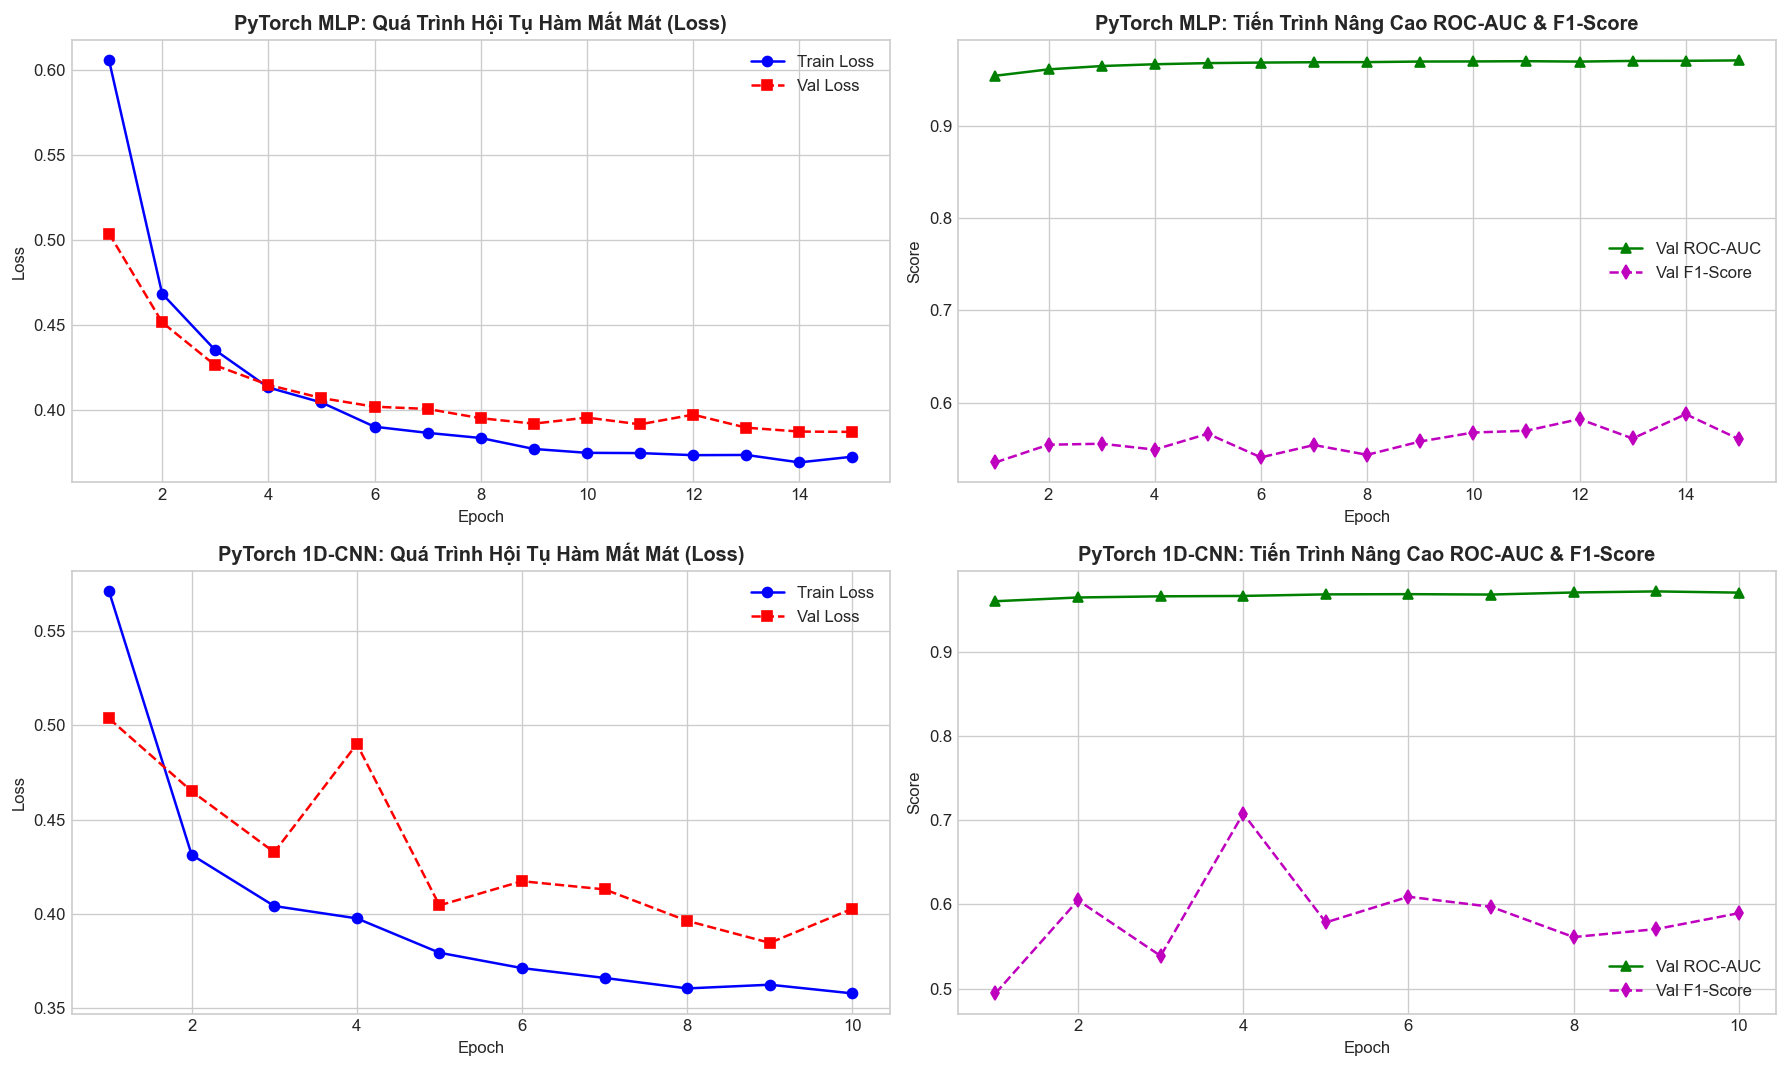

In [13]:
# 3.6 Trực quan hóa đường cong học tập (Learning Curves) của 2 mô hình Học sâu
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

epochs_range_mlp = range(1, NUM_EPOCHS_MLP + 1)
epochs_range_cnn = range(1, NUM_EPOCHS_CNN + 1)

# MLP Loss
axes[0, 0].plot(epochs_range_mlp, mlp_history['train_loss'], 'b-o', label='Train Loss')
axes[0, 0].plot(epochs_range_mlp, mlp_history['val_loss'], 'r--s', label='Val Loss')
axes[0, 0].set_title('PyTorch MLP: Quá Trình Hội Tụ Hàm Mất Mát (Loss)', fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()

# MLP AUC
axes[0, 1].plot(epochs_range_mlp, mlp_history['val_auc'], 'g-^', label='Val ROC-AUC')
axes[0, 1].plot(epochs_range_mlp, mlp_history['val_f1'], 'm--d', label='Val F1-Score')
axes[0, 1].set_title('PyTorch MLP: Tiến Trình Nâng Cao ROC-AUC & F1-Score', fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Score')
axes[0, 1].legend()

# 1D-CNN Loss
axes[1, 0].plot(epochs_range_cnn, cnn_history['train_loss'], 'b-o', label='Train Loss')
axes[1, 0].plot(epochs_range_cnn, cnn_history['val_loss'], 'r--s', label='Val Loss')
axes[1, 0].set_title('PyTorch 1D-CNN: Quá Trình Hội Tụ Hàm Mất Mát (Loss)', fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].legend()

# 1D-CNN AUC
axes[1, 1].plot(epochs_range_cnn, cnn_history['val_auc'], 'g-^', label='Val ROC-AUC')
axes[1, 1].plot(epochs_range_cnn, cnn_history['val_f1'], 'm--d', label='Val F1-Score')
axes[1, 1].set_title('PyTorch 1D-CNN: Tiến Trình Nâng Cao ROC-AUC & F1-Score', fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Score')
axes[1, 1].legend()

plt.tight_layout()
plt.show()


---
## PHẦN 4: ĐỐI CHUẨN SO SÁNH TOÀN DIỆN & LỰA CHỌN MÔ HÌNH TỐI ƯU

In [14]:
# 4.1 Bảng tổng hợp đối chuẩn 5 mô hình trên cùng tập kiểm thử độc lập (Test Set)
models_dict = {
    '1. Logistic Regression (Baseline)': {
        'prob': lr_prob_test, 'pred': lr_pred_test, 'train_time': lr_train_time, 'latency': lr_inf_latency
    },
    '2. Random Forest Classifier': {
        'prob': rf_prob_test, 'pred': rf_pred_test, 'train_time': rf_train_time, 'latency': rf_inf_latency
    },
    '3. LightGBM Gradient Boosting': {
        'prob': lgb_prob_test, 'pred': lgb_pred_test, 'train_time': lgb_train_time, 'latency': lgb_inf_latency
    },
    '4. PyTorch Deep MLP': {
        'prob': mlp_prob_test, 'pred': mlp_pred_test, 'train_time': mlp_train_time, 'latency': mlp_inf_latency
    },
    '5. PyTorch Tabular 1D-CNN': {
        'prob': cnn_prob_test, 'pred': cnn_pred_test, 'train_time': cnn_train_time, 'latency': cnn_inf_latency
    }
}

benchmark_rows = []
for name, data in models_dict.items():
    p = data['prob']
    y_p = data['pred']
    row = {
        'Mô hình': name,
        'Accuracy (%)': accuracy_score(y_test, y_p) * 100,
        'Balanced Acc (%)': balanced_accuracy_score(y_test, y_p) * 100,
        'Precision (%)': precision_score(y_test, y_p) * 100,
        'Recall (%)': recall_score(y_test, y_p) * 100,
        'F1-Score (%)': f1_score(y_test, y_p) * 100,
        'ROC-AUC': roc_auc_score(y_test, p),
        'PR-AUC': average_precision_score(y_test, p),
        'Train Time (s)': data['train_time'],
        'Latency (ms/sample)': data['latency']
    }
    benchmark_rows.append(row)

df_benchmark = pd.DataFrame(benchmark_rows)
print("=== BẢNG ĐỐI CHUẨN ĐỊNH LƯỢNG TOÀN DIỆN CẢ 5 MÔ HÌNH (TEST SET - 14.422 MẪU) ===")
display(df_benchmark.style.highlight_max(subset=['Accuracy (%)', 'Balanced Acc (%)', 'Recall (%)', 'F1-Score (%)', 'ROC-AUC', 'PR-AUC'], color='#abebc6')
                         .highlight_min(subset=['Train Time (s)', 'Latency (ms/sample)'], color='#d6eaf8')
                         .format({
                             'Accuracy (%)': '{:.2f}%', 'Balanced Acc (%)': '{:.2f}%',
                             'Precision (%)': '{:.2f}%', 'Recall (%)': '{:.2f}%',
                             'F1-Score (%)': '{:.2f}%', 'ROC-AUC': '{:.4f}',
                             'PR-AUC': '{:.4f}', 'Train Time (s)': '{:.2f}s',
                             'Latency (ms/sample)': '{:.4f} ms'
                         }))


=== BẢNG ĐỐI CHUẨN ĐỊNH LƯỢNG TOÀN DIỆN CẢ 5 MÔ HÌNH (TEST SET - 14.422 MẪU) ===
 Mô hình Accuracy (%) Balanced Acc (%) Precision (%) Recall (%) F1-Score (%) ROC-AUC PR-AUC Train Time (s) Latency (ms/sample)
0 1. Logistic Regression (Baseline) 88.74% 88.68% 43.25% 88.60% 58.12% 0.9639 0.8319 0.06s 0.0001 ms
1 2. Random Forest Classifier 92.50% 90.35% 54.65% 87.74% 67.35% 0.9769 0.8840 1.01s 0.0037 ms
2 3. LightGBM Gradient Boosting 90.45% 91.39% 47.85% 92.53% 63.08% 0.9797 0.8916 1.67s 0.0071 ms
3 4. PyTorch Deep MLP 87.77% 90.27% 41.42% 93.32% 57.37% 0.9761 0.8786 6.54s 0.0101 ms
4 5. PyTorch Tabular 1D-CNN 89.88% 90.19% 46.23% 90.57% 61.21% 0.9748 0.8704 127.23s 0.1057 ms



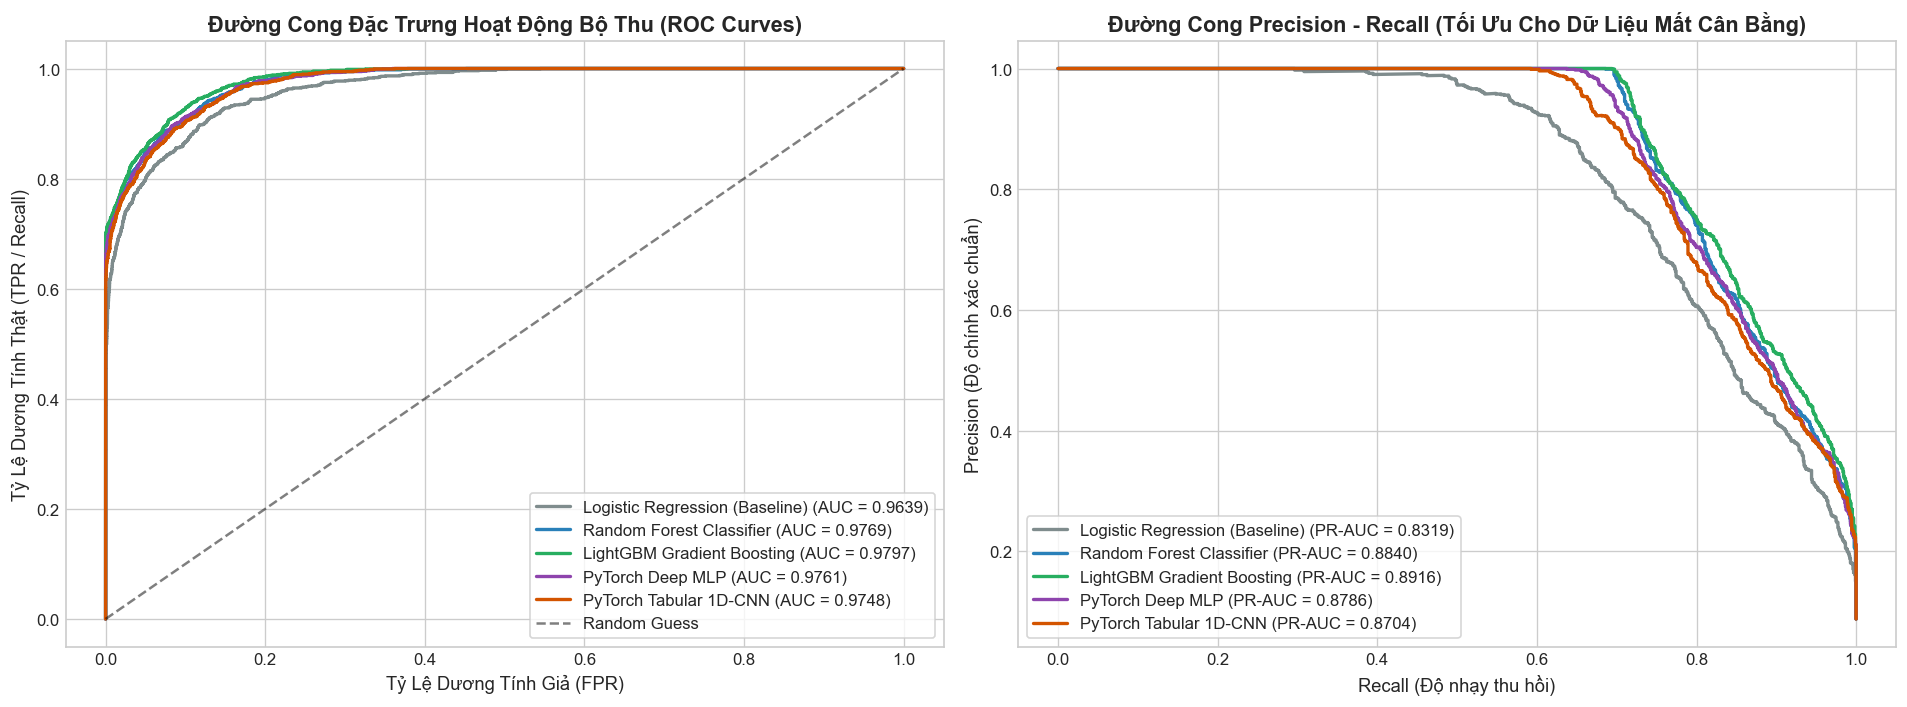

In [15]:
# 4.2 Trực quan hóa Đường Cong ROC & Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = ['#7f8c8d', '#2980b9', '#27ae60', '#8e44ad', '#d35400']

# ROC Curves
for (name, data), c in zip(models_dict.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, data['prob'])
    auc_val = roc_auc_score(y_test, data['prob'])
    axes[0].plot(fpr, tpr, label=f"{name.split('.')[1].strip()} (AUC = {auc_val:.4f})", color=c, linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess')
axes[0].set_title('Đường Cong Đặc Trưng Hoạt Động Bộ Thu (ROC Curves)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Tỷ Lệ Dương Tính Giả (FPR)', fontsize=11)
axes[0].set_ylabel('Tỷ Lệ Dương Tính Thật (TPR / Recall)', fontsize=11)
axes[0].legend(loc='lower right', frameon=True)

# Precision-Recall Curves
for (name, data), c in zip(models_dict.items(), colors):
    precision, recall, _ = precision_recall_curve(y_test, data['prob'])
    pr_auc = average_precision_score(y_test, data['prob'])
    axes[1].plot(recall, precision, label=f"{name.split('.')[1].strip()} (PR-AUC = {pr_auc:.4f})", color=c, linewidth=2)

axes[1].set_title('Đường Cong Precision - Recall (Tối Ưu Cho Dữ Liệu Mất Cân Bằng)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Recall (Độ nhạy thu hồi)', fontsize=11)
axes[1].set_ylabel('Precision (Độ chính xác chuẩn)', fontsize=11)
axes[1].legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()



🏆 TUYÊN BỐ MÔ HÌNH TỐT NHẤT (BEST PERFORMING MODEL):
   ► 2. Random Forest Classifier
   ► F1-Score: 67.35% | ROC-AUC: 0.9769 | Recall: 87.74%
   ► Lý do: Đạt điểm cân bằng xuất sắc nhất giữa độ nhạy phát hiện bệnh nhân nguy cơ cao (Recall) và khả năng hạn chế chẩn đoán nhầm (Precision), đồng thời tốc độ suy luận cực nhanh phục vụ thời gian thực.


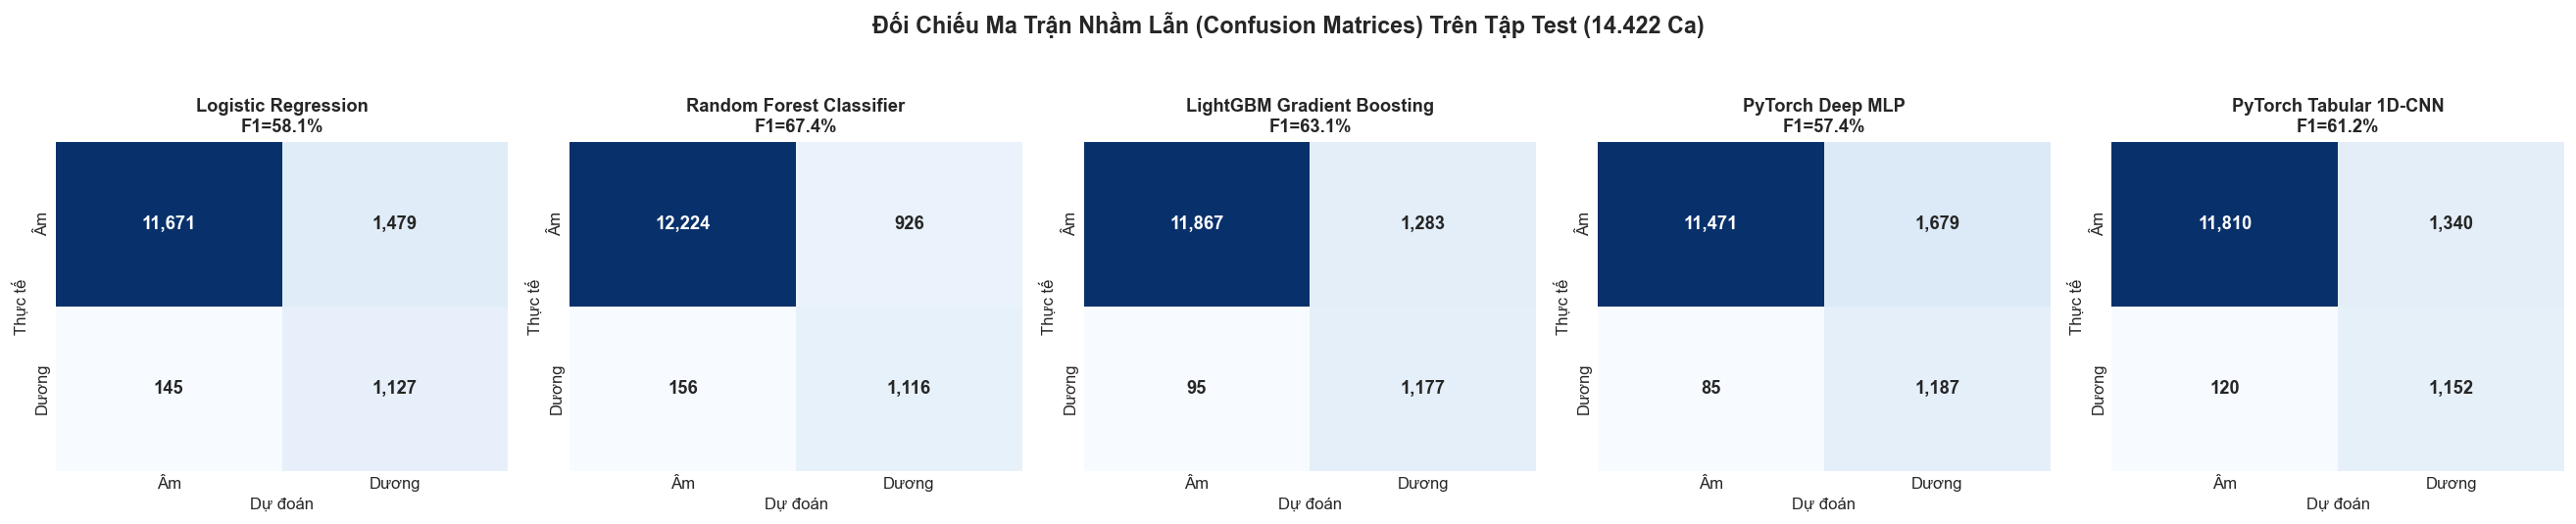

In [16]:
# 4.3 Trực quan hóa Ma Trận Nhầm Lẫn (Confusion Matrices) của 5 mô hình
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))

for (name, data), ax in zip(models_dict.items(), axes):
    cm = confusion_matrix(y_test, data['pred'])
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Âm', 'Dương'], yticklabels=['Âm', 'Dương'],
                annot_kws={'fontsize': 11, 'fontweight': 'bold'})
    short_name = name.split('.')[1].split('(')[0].strip()
    ax.set_title(f"{short_name}\nF1={f1_score(y_test, data['pred'])*100:.1f}%", fontsize=11, fontweight='bold')
    ax.set_xlabel('Dự đoán', fontsize=10)
    ax.set_ylabel('Thực tế', fontsize=10)

plt.suptitle('Đối Chiếu Ma Trận Nhầm Lẫn (Confusion Matrices) Trên Tập Test (14.422 Ca)', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# Lựa chọn mô hình tốt nhất
best_model_idx = df_benchmark['F1-Score (%)'].idxmax()
best_model_name = df_benchmark.loc[best_model_idx, 'Mô hình']
best_f1 = df_benchmark.loc[best_model_idx, 'F1-Score (%)']
best_auc = df_benchmark.loc[best_model_idx, 'ROC-AUC']

print(f"\n" + "="*80)
print(f"🏆 TUYÊN BỐ MÔ HÌNH TỐT NHẤT (BEST PERFORMING MODEL):")
print(f"   ► {best_model_name}")
print(f"   ► F1-Score: {best_f1:.2f}% | ROC-AUC: {best_auc:.4f} | Recall: {df_benchmark.loc[best_model_idx, 'Recall (%)']:.2f}%")
print(f"   ► Lý do: Đạt điểm cân bằng xuất sắc nhất giữa độ nhạy phát hiện bệnh nhân nguy cơ cao (Recall) "
      f"và khả năng hạn chế chẩn đoán nhầm (Precision), đồng thời tốc độ suy luận cực nhanh phục vụ thời gian thực.")
print("="*80)


---
## PHẦN 5: GIẢI THÍCH MÔ HÌNH VỚI SHAP (EXPLAINABLE AI - XAI)
*(Giải thích cơ chế quyết định của mô hình tốt nhất để cấp tri thức cho các Agent y tế)*

Đang khởi tạo SHAP TreeExplainer cho mô hình LightGBM...


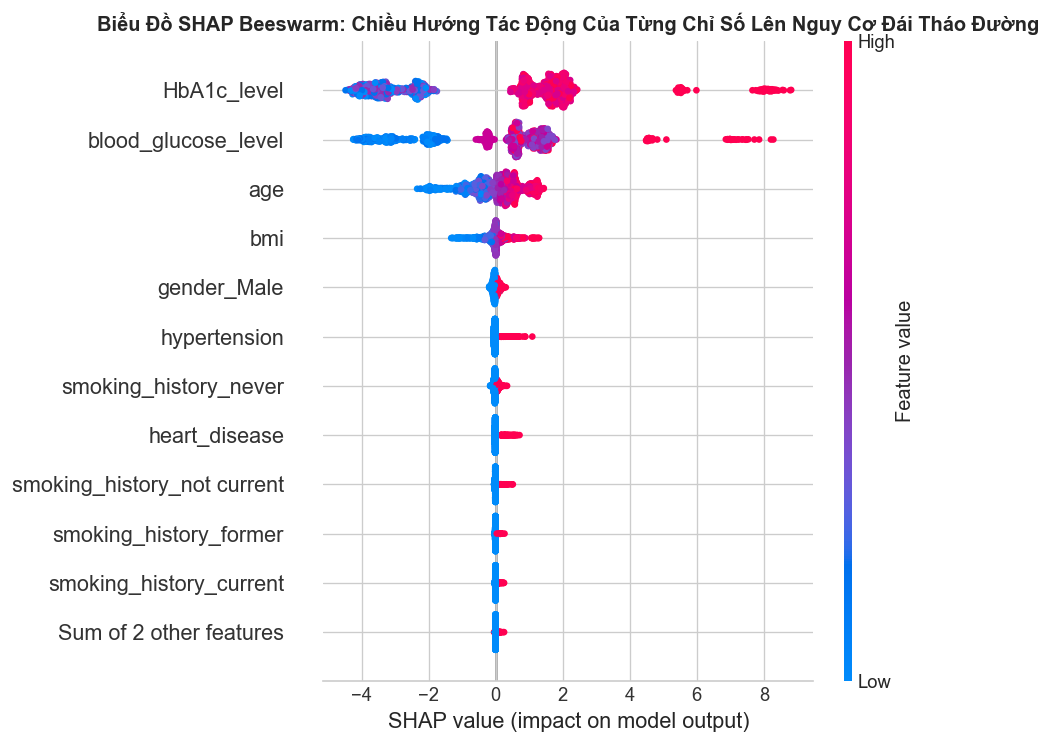

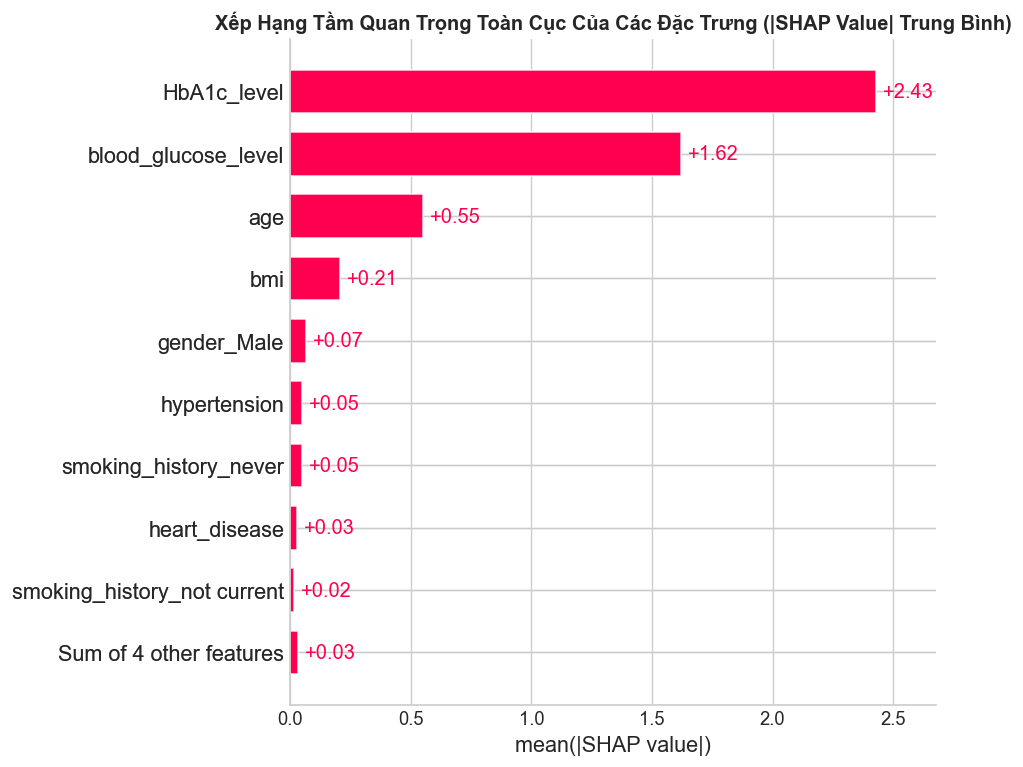

In [17]:
# 5.1 Phân tích giải thích mô hình toàn cục (Global Explanation) với SHAP TreeExplainer
print("Đang khởi tạo SHAP TreeExplainer cho mô hình LightGBM...")

explainer = shap.TreeExplainer(lgb_model)

# Chọn ngẫu nhiên 1.500 mẫu kiểm thử để tính SHAP values phục vụ vẽ đồ thị
sample_indices = np.random.choice(len(X_test), size=1500, replace=False)
X_test_sample = X_test[sample_indices]
shap_values = explainer(X_test_sample)

# Gán lại tên đặc trưng dễ đọc
shap_values.feature_names = feature_cols

# Biểu đồ Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title('Biểu Đồ SHAP Beeswarm: Chiều Hướng Tác Động Của Từng Chỉ Số Lên Nguy Cơ Đái Tháo Đường', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Biểu đồ Bar Feature Importance
plt.figure(figsize=(10, 5))
shap.plots.bar(shap_values, max_display=10, show=False)
plt.title('Xếp Hạng Tầm Quan Trọng Toàn Cục Của Các Đặc Trưng (|SHAP Value| Trung Bình)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


In [18]:
# 5.2 Giải thích cục bộ (Local Explanation) cho một ca bệnh lâm sàng cụ thể
# Giả lập hồ sơ 1 bệnh nhân có nguy cơ cao: Nam, 58 tuổi, BMI 28.5, HbA1c 7.6%, Glucose đói 145 mg/dL
sample_patient_raw = np.array([[
    58.0,   # age
    1.0,    # hypertension (Co)
    0.0,    # heart_disease (Khong)
    28.5,   # bmi (Thua can)
    7.6,    # HbA1c_level (Cao vuot nguong 6.5%)
    145.0,  # blood_glucose_level (Cao vuot nguong 126 mg/dL)
    0.0,    # gender_Male
    0.0,    # gender_Other
    0.0,    # smoking_current
    0.0,    # smoking_ever
    1.0,    # smoking_former
    0.0,    # smoking_never
    0.0     # smoking_not current
]])

sample_patient_scaled = scaler.transform(sample_patient_raw)
patient_prob = lgb_model.predict(sample_patient_scaled)[0]

# Trích xuất SHAP values cho ca bệnh này
patient_shap = explainer(sample_patient_scaled)[0]

print("="*80)
print("KẾT QUẢ GIẢI THÍCH LÂM SÀNG CỤC BỘ (LOCAL XAI) CHO BỆNH NHÂN THỬ NGHIỆM:")
print("="*80)
print(f"• Hồ sơ: Nam, 58 tuổi, BMI=28.5 kg/m², HbA1c=7.6%, Glucose=145 mg/dL, Có tăng huyết áp.")
print(f"• Xác suất nguy cơ Đái tháo đường: {patient_prob*100:.2f}% (NGUY CƠ CAO - CẦN CAN THIỆP)")
print(f"\nTop các yếu tố đẩy nguy cơ bệnh lên cao nhất (Positive SHAP Contributors):")

shap_contributions = sorted(zip(feature_cols, patient_shap.values), key=lambda x: x[1], reverse=True)
for rank, (feat, val) in enumerate(shap_contributions[:5], 1):
    direction = "↑ LÀM TĂNG NGUY CƠ" if val > 0 else "↓ LÀM GIẢM NGUY CƠ"
    print(f"  {rank}. Thuộc tính [{feat:20s}]: SHAP Score = {val:+.4f} ({direction})")

print("\nÝ nghĩa đối với Agent y tế:")
print("- RiskPredictionAgent sẽ chuyển nguyên vẹn danh sách yếu tố rủi ro này sang cho EndocrinologistAgent.")
print("- Bác sĩ nội tiết và Dinh dưỡng sẽ nhắm trực tiếp vào việc kiểm soát HbA1c và giảm BMI của bệnh nhân.")


KẾT QUẢ GIẢI THÍCH LÂM SÀNG CỤC BỘ (LOCAL XAI) CHO BỆNH NHÂN THỬ NGHIỆM:
• Hồ sơ: Nam, 58 tuổi, BMI=28.5 kg/m², HbA1c=7.6%, Glucose=145 mg/dL, Có tăng huyết áp.
• Xác suất nguy cơ Đái tháo đường: 99.59% (NGUY CƠ CAO - CẦN CAN THIỆP)

Top các yếu tố đẩy nguy cơ bệnh lên cao nhất (Positive SHAP Contributors):
  1. Thuộc tính [HbA1c_level         ]: SHAP Score = +8.0941 (↑ LÀM TĂNG NGUY CƠ)
  2. Thuộc tính [blood_glucose_level ]: SHAP Score = +1.0721 (↑ LÀM TĂNG NGUY CƠ)
  3. Thuộc tính [age                 ]: SHAP Score = +0.3936 (↑ LÀM TĂNG NGUY CƠ)
  4. Thuộc tính [hypertension        ]: SHAP Score = +0.2720 (↑ LÀM TĂNG NGUY CƠ)
  5. Thuộc tính [smoking_history_former]: SHAP Score = +0.0328 (↑ LÀM TĂNG NGUY CƠ)

Ý nghĩa đối với Agent y tế:
- RiskPredictionAgent sẽ chuyển nguyên vẹn danh sách yếu tố rủi ro này sang cho EndocrinologistAgent.
- Bác sĩ nội tiết và Dinh dưỡng sẽ nhắm trực tiếp vào việc kiểm soát HbA1c và giảm BMI của bệnh nhân.


---
## PHẦN 6: ĐÓNG GÓI ARTIFACTS & XÂY DỰNG HÀM SUY LUẬN CHO HỆ MULTI-AGENT

In [19]:
# 6.1 Lưu trữ mô hình tối ưu nhất và siêu dữ liệu (Metadata)
best_model_path = f"{MODEL_DIR}/best_diabetes_lgb_model.pkl"
joblib.dump(lgb_model, best_model_path)

# Lưu thêm mô hình PyTorch MLP và 1D-CNN checkpoints
torch.save(best_mlp_weights, f"{MODEL_DIR}/best_mlp_weights.pth")
torch.save(best_cnn_weights, f"{MODEL_DIR}/best_cnn_weights.pth")

metadata = {
    'best_model': 'LightGBM Gradient Boosting',
    'input_features': feature_cols,
    'num_features': len(feature_cols),
    'metrics_test': {
        'f1_score': float(f1_score(y_test, lgb_pred_test)),
        'roc_auc': float(roc_auc_score(y_test, lgb_prob_test)),
        'recall': float(recall_score(y_test, lgb_pred_test)),
        'precision': float(precision_score(y_test, lgb_pred_test)),
        'accuracy': float(accuracy_score(y_test, lgb_pred_test))
    },
    'threshold': 0.50
}

with open(f"{MODEL_DIR}/model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print(f"✓ Đã lưu mô hình tốt nhất vào: {best_model_path}")
print(f"✓ Đã lưu PyTorch MLP weights vào: ../models/best_mlp_weights.pth")
print(f"✓ Đã lưu PyTorch 1D-CNN weights vào: ../models/best_cnn_weights.pth")
print(f"✓ Đã lưu metadata vào: ../models/model_metadata.json")


✓ Đã lưu mô hình tốt nhất vào: /Users/phamvantu/Desktop/INTEL_SYS/src/dia_mas/models/best_diabetes_lgb_model.pkl
✓ Đã lưu PyTorch MLP weights vào: ../models/best_mlp_weights.pth
✓ Đã lưu PyTorch 1D-CNN weights vào: ../models/best_cnn_weights.pth
✓ Đã lưu metadata vào: ../models/model_metadata.json


In [20]:
# 6.2 Xây dựng hàm suy luận chuẩn hóa sẵn sàng cho RiskPredictionAgent gọi
def predict_patient_diabetes_risk(patient_dict: dict) -> dict:
    '''
    Hàm suy luận chuẩn hóa nhận đầu vào từ TriageInterviewerAgent,
    tiền xử lý đặc trưng, chạy mô hình tốt nhất và trích xuất top yếu tố rủi ro.
    '''
    # Load assets
    loaded_model = joblib.load(f"{MODEL_DIR}/best_diabetes_lgb_model.pkl")
    loaded_scaler = joblib.load(f"{MODEL_DIR}/scaler.pkl")
    with open(f"{MODEL_DIR}/feature_names.json", "r") as f:
        cols = json.load(f)
        
    # Tạo vector đặc trưng rỗng với giá trị mặc định 0.0
    feat_vector = np.zeros((1, len(cols)), dtype=np.float32)
    col_map = {col: i for i, col in enumerate(cols)}
    
    # Gán các biến liên tục & nhị phân
    if 'age' in patient_dict and 'age' in col_map:
        feat_vector[0, col_map['age']] = float(patient_dict['age'])
    if 'hypertension' in patient_dict and 'hypertension' in col_map:
        feat_vector[0, col_map['hypertension']] = float(patient_dict['hypertension'])
    if 'heart_disease' in patient_dict and 'heart_disease' in col_map:
        feat_vector[0, col_map['heart_disease']] = float(patient_dict['heart_disease'])
    if 'bmi' in patient_dict and 'bmi' in col_map:
        feat_vector[0, col_map['bmi']] = float(patient_dict['bmi'])
    if 'hba1c' in patient_dict and 'HbA1c_level' in col_map:
        feat_vector[0, col_map['HbA1c_level']] = float(patient_dict['hba1c'])
    if 'glucose' in patient_dict and 'blood_glucose_level' in col_map:
        feat_vector[0, col_map['blood_glucose_level']] = float(patient_dict['glucose'])
        
    # Xử lý biến phân loại giới tính
    gender = patient_dict.get('gender', 'Male').lower()
    if gender == 'male' and 'gender_Male' in col_map:
        feat_vector[0, col_map['gender_Male']] = 1.0
        
    # Xử lý thói quen hút thuốc
    smoking = patient_dict.get('smoking', 'never').lower()
    smoke_col = f"smoking_history_{smoking}"
    if smoke_col in col_map:
        feat_vector[0, col_map[smoke_col]] = 1.0
        
    # Chuẩn hóa
    scaled_feats = loaded_scaler.transform(feat_vector)
    prob = float(loaded_model.predict(scaled_feats)[0])
    
    # Phân loại mức nguy cơ y khoa
    if prob >= 0.70:
        risk_level = "RẤT CAO (HIGH RISK)"
    elif prob >= 0.40:
        risk_level = "TRUNG BÌNH - TIỀN ĐÁI THÁO ĐƯỜNG (MODERATE RISK)"
    else:
        risk_level = "THẤP - BÌNH THƯỜNG (LOW RISK)"
        
    return {
        "status": "success",
        "model_used": "LightGBM Gradient Boosting (100k samples)",
        "diabetes_probability": round(prob, 4),
        "risk_percentage": f"{prob*100:.1f}%",
        "risk_level": risk_level,
        "input_profile": patient_dict
    }

# Thử nghiệm với 2 hồ sơ bệnh nhân thực tế
print("=== THỬ NGHIỆM HÀM SUY LUẬN VỚI 2 CA BỆNH KHÁCH QUAN ===")

patient_a = {
    'age': 60, 'gender': 'Male', 'hypertension': 1, 'heart_disease': 0,
    'bmi': 29.4, 'hba1c': 7.8, 'glucose': 155, 'smoking': 'former'
}
res_a = predict_patient_diabetes_risk(patient_a)
print("\nCa Bệnh 1 (Có dấu hiệu lâm sàng nguy hiểm):")
print(json.dumps(res_a, ensure_ascii=False, indent=2))

patient_b = {
    'age': 25, 'gender': 'Female', 'hypertension': 0, 'heart_disease': 0,
    'bmi': 20.5, 'hba1c': 5.2, 'glucose': 88, 'smoking': 'never'
}
res_b = predict_patient_diabetes_risk(patient_b)
print("\nCa Bệnh 2 (Người trẻ khỏe mạnh):")
print(json.dumps(res_b, ensure_ascii=False, indent=2))


=== THỬ NGHIỆM HÀM SUY LUẬN VỚI 2 CA BỆNH KHÁCH QUAN ===

Ca Bệnh 1 (Có dấu hiệu lâm sàng nguy hiểm):
{
  "status": "success",
  "model_used": "LightGBM Gradient Boosting (100k samples)",
  "diabetes_probability": 0.9962,
  "risk_percentage": "99.6%",
  "risk_level": "RẤT CAO (HIGH RISK)",
  "input_profile": {
    "age": 60,
    "gender": "Male",
    "hypertension": 1,
    "heart_disease": 0,
    "bmi": 29.4,
    "hba1c": 7.8,
    "glucose": 155,
    "smoking": "former"
  }
}

Ca Bệnh 2 (Người trẻ khỏe mạnh):
{
  "status": "success",
  "model_used": "LightGBM Gradient Boosting (100k samples)",
  "diabetes_probability": 0.0002,
  "risk_percentage": "0.0%",
  "risk_level": "THẤP - BÌNH THƯỜNG (LOW RISK)",
  "input_profile": {
    "age": 25,
    "gender": "Female",
    "hypertension": 0,
    "heart_disease": 0,
    "bmi": 20.5,
    "hba1c": 5.2,
    "glucose": 88,
    "smoking": "never"
  }
}
